In [10]:
%pip install numpy matplotlib


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

print("NumPy Version:", np.__version__)
print("Matplotlib Version:", matplotlib.__version__)

print("Oscillations & Resonance Simulator")
print("Libraries imported successfully!")

NumPy Version: 2.5.5
Matplotlib Version: 3.11.2
Oscillations & Resonance Simulator
Libraries imported successfully!


In [14]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

print("NumPy Version:", np.__version__)

print("Matplotlib Version:", matplotlib.__version__)

print("Oscillations & Resonance Simulator")

print("Libraries imported successfully!")

NumPy Version: 2.5.5
Matplotlib Version: 3.11.2
Oscillations & Resonance Simulator
Libraries imported successfully!


In [ ]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

print("NumPy Version:", np.__version__)

print("Matplotlib Version:", matplotlib.__version__)

print("Oscillations & Resonance Simulator")

print("Libraries imported successfully!")

NumPy Version: 2.5.5
Matplotlib Version: 3.11.2
Oscillations & Resonance Simulator
Libraries imported successfully!


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

print("Oscillations & Resonance Simulator")
print("Simulation is starting...")


Oscillations & Resonance Simulator
Simulation is starting...


In [30]:
# Physical parameters

mass = 2.0
spring_constant = 40.0
damping_coefficient = 0.5

initial_position = 0.15
initial_velocity = 0.0

force_amplitude = 5.0
driving_frequency = 1.0

# Simulation settings

time_step = 0.01
total_time = 60

time = np.arange(0, total_time, time_step)

# Natural angular frequency

natural_frequency = np.sqrt(
    spring_constant / mass
)

print("Physical Parameters")
print("----------------------------")

print(f"Mass: {mass} kg")
print(f"Spring Constant: {spring_constant} N/m")
print(f"Damping Coefficient: {damping_coefficient} Ns/m")

print(f"Natural Frequency: {natural_frequency:.3f} rad/s")

Physical Parameters
----------------------------
Mass: 2.0 kg
Spring Constant: 40.0 N/m
Damping Coefficient: 0.5 Ns/m
Natural Frequency: 4.472 rad/s


In [31]:
def acceleration(position, velocity, t, force_frequency):

    external_force = (
        force_amplitude *
        np.cos(force_frequency * t)
    )

    spring_force = -spring_constant * position

    damping_force = -damping_coefficient * velocity

    net_force = (
        spring_force +
        damping_force +
        external_force
    )

    return net_force / mass

In [32]:
def simulate_oscillator(force_frequency):

    position = np.zeros(len(time))
    velocity = np.zeros(len(time))
    acceleration_values = np.zeros(len(time))

    position[0] = initial_position
    velocity[0] = initial_velocity

    def derivatives(state, t):

        x, v = state

        a = acceleration(
            x, v, t, force_frequency
        )

        return np.array([v, a])

    for i in range(len(time) - 1):

        t = time[i]
        dt = time_step

        state = np.array([
            position[i],
            velocity[i]
        ])

        # Runge-Kutta 4th Order Method

        k1 = derivatives(state, t)

        k2 = derivatives(
            state + 0.5 * dt * k1,
            t + 0.5 * dt
        )

        k3 = derivatives(
            state + 0.5 * dt * k2,
            t + 0.5 * dt
        )

        k4 = derivatives(
            state + dt * k3,
            t + dt
        )

        new_state = state + (
            dt / 6
        ) * (
            k1 + 2*k2 + 2*k3 + k4
        )

        position[i + 1] = new_state[0]
        velocity[i + 1] = new_state[1]

    for i in range(len(time)):

        acceleration_values[i] = acceleration(
            position[i],
            velocity[i],
            time[i],
            force_frequency
        )

    return position, velocity, acceleration_values

In [33]:
test_position, test_velocity, test_acceleration = (
    simulate_oscillator(driving_frequency)
)

print("Simulation Test")
print("----------------------")

print("Position:", test_position[:5])
print("Velocity:", test_velocity[:5])
print("Acceleration:", test_acceleration[:5])

Simulation Test
----------------------
Position: [0.15       0.14997502 0.14990022 0.14977581 0.14960213]
Velocity: [ 0.         -0.00499251 -0.00996507 -0.01491032 -0.01982092]
Acceleration: [-0.5        -0.49837735 -0.49601304 -0.49291361 -0.48908701]


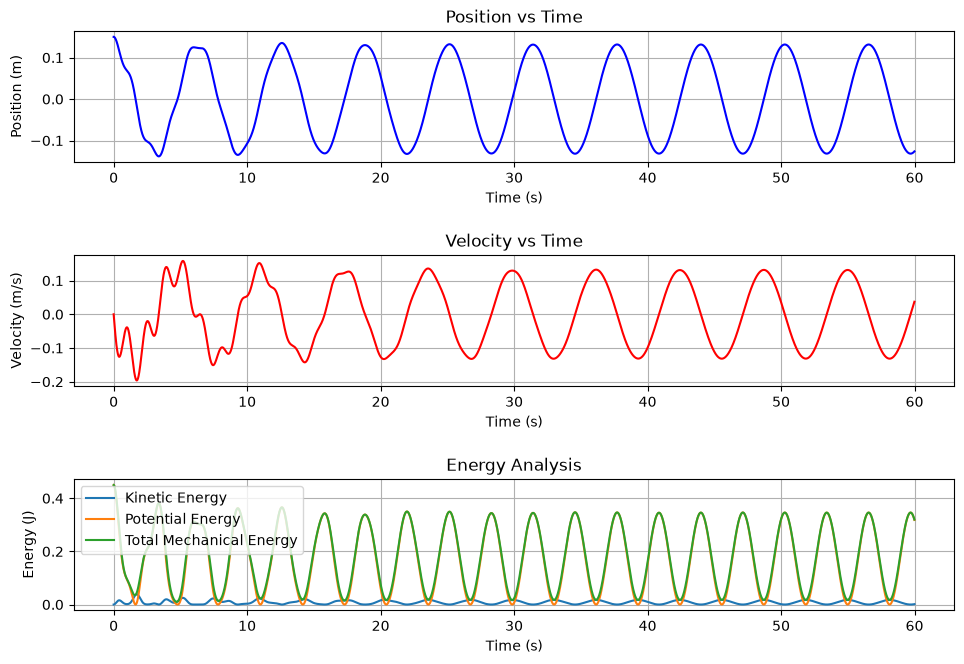

In [37]:
# Calculate energies

position, velocity, acceleration_values = simulate_oscillator(driving_frequency)


kinetic_energy = 0.5 * mass * velocity**2

potential_energy = (0.5 * spring_constant * position**2)

total_energy = kinetic_energy + potential_energy


# Create plots

fig, axes = plt.subplots(3, 1, figsize=(10, 7))


# Position vs Time

axes[0].plot(time, position, color="blue")

axes[0].set_title("Position vs Time")
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Position (m)")
axes[0].grid(True)


# Velocity vs Time

axes[1].plot(time, velocity, color="red")

axes[1].set_title("Velocity vs Time")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Velocity (m/s)")
axes[1].grid(True)


# Energy Analysis

axes[2].plot(
    time,
    kinetic_energy,
    label="Kinetic Energy"
)

axes[2].plot(
    time,
    potential_energy,
    label="Potential Energy"
)

axes[2].plot(
    time,
    total_energy,
    label="Total Mechanical Energy"
)

axes[2].set_title("Energy Analysis")
axes[2].set_xlabel("Time (s)")
axes[2].set_ylabel("Energy (J)")
axes[2].legend()
axes[2].grid(True)


plt.tight_layout(pad=2.0)

import os
os.makedirs("images" , exist_ok=True)

fig.savefig(
    "images/oscillation_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



Resonance Frequency: 4.538461538461538 rad/s
Maximum Amplitude: 1.9586773185653197 m


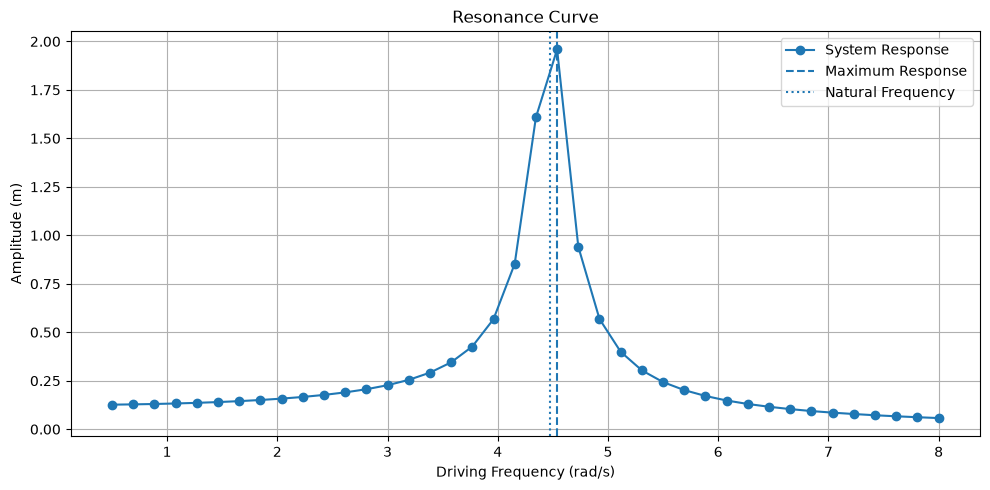

In [35]:
# Frequency range

frequencies = np.linspace(0.5, 8.0, 40)

amplitudes = []

# Analyze different driving frequencies

for frequency in frequencies:

    x, v, a = simulate_oscillator(frequency)

    # Ignore the initial transient response

    steady_state_start = int(0.7 * len(time))

    steady_state_position = x[steady_state_start:]

    amplitude = (
        np.max(steady_state_position) -
        np.min(steady_state_position)
    ) / 2

    amplitudes.append(amplitude)


amplitudes = np.array(amplitudes)

# Find maximum amplitude

resonance_index = np.argmax(amplitudes)

resonance_frequency = frequencies[resonance_index]

print("Resonance Frequency:", resonance_frequency, "rad/s")

print("Maximum Amplitude:", amplitudes[resonance_index], "m")


# Plot resonance curve

plt.figure(figsize=(10, 5))

plt.plot(
    frequencies,
    amplitudes,
    marker="o",
    label="System Response"
)

plt.axvline(
    resonance_frequency,
    linestyle="--",
    label="Maximum Response"
)

plt.axvline(
    natural_frequency,
    linestyle=":",
    label="Natural Frequency"
)

plt.title("Resonance Curve")

plt.xlabel("Driving Frequency (rad/s)")

plt.ylabel("Amplitude (m)")

plt.legend()

plt.grid(True)

plt.tight_layout()
plt.savefig(
    "images/resonance_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [36]:
print("=" * 50)
print("OSCILLATIONS & RESONANCE SIMULATOR")
print("FINAL SIMULATION REPORT")
print("=" * 50)

print("\nPHYSICAL PARAMETERS")
print("-" * 50)

print(f"Mass: {mass} kg")
print(f"Spring Constant: {spring_constant} N/m")
print(f"Damping Coefficient: {damping_coefficient} Ns/m")

print("\nFREQUENCY ANALYSIS")
print("-" * 50)

print(f"Natural Frequency: {natural_frequency:.3f} rad/s")

print(f"Driving Frequency: {driving_frequency:.3f} rad/s")

print(f"Resonance Frequency: {resonance_frequency:.3f} rad/s")

print("\nSIMULATION RESULTS")
print("-" * 50)

print(f"Maximum Amplitude: {amplitudes[resonance_index]:.4f} m")

print(f"Maximum Velocity: {np.max(np.abs(test_velocity)):.4f} m/s")

print(f"Maximum Acceleration: {np.max(np.abs(test_acceleration)):.4f} m/s^2")

print(f"Final Position: {test_position[-1]:.4f} m")

print("\nSIMULATION STATUS")
print("-" * 50)

print("Simulation completed successfully!")

print("=" * 50)

OSCILLATIONS & RESONANCE SIMULATOR
FINAL SIMULATION REPORT

PHYSICAL PARAMETERS
--------------------------------------------------
Mass: 2.0 kg
Spring Constant: 40.0 N/m
Damping Coefficient: 0.5 Ns/m

FREQUENCY ANALYSIS
--------------------------------------------------
Natural Frequency: 4.472 rad/s
Driving Frequency: 1.000 rad/s
Resonance Frequency: 4.538 rad/s

SIMULATION RESULTS
--------------------------------------------------
Maximum Amplitude: 1.9587 m
Maximum Velocity: 0.1963 m/s
Maximum Acceleration: 0.5000 m/s^2
Final Position: -0.1262 m

SIMULATION STATUS
--------------------------------------------------
Simulation completed successfully!
